# Предобработка данных и регрессия на датасете «House Prices»

## 1. Титульный лист

**Дисциплина:** Машинное обучение и ИИ  
**Модуль 2:** Предобработка данных и базовые алгоритмы регрессии/классификации  
**Датасет:** *House Prices — Advanced Regression Techniques*  
**Выполнила:** Володина Александра Александровна  
**Группа:** ПКТб-23-1  
**Преподаватель:** Спирин Игорь Сергеевич  
**Ссылка на репозиторий:** [ml-course-volodina](https://github.com/VolodinaAlexandra/ml-course-volodina)  
**Путь к модулю:** `module-2-house-prices/notebook.ipynb`  
**Дата сдачи:** 2026-10-13

## 2. Введение

**Задача:** по характеристикам дома предсказать `SalePrice` — непрерывную цену продажи в долларах. Это регрессия: результатом является число, а не одна из заранее заданных категорий.

ML-проект включает изучение исходных данных, обработку пропусков, создание признаков, обучение на части наблюдений и проверку на отложенной части. Такой порядок показывает, насколько модель переносится на дома, которых она не видела.

**Основная метрика — RMSE в логарифмической шкале:** она согласуется с обучением на `log1p(SalePrice)` и сильнее штрафует большие относительные ошибки. MAE в долларах помогает понять типичную ошибку в привычных единицах; R² показывает долю объяснённой изменчивости, но не измеряет ошибку в долларах.

**Цели работы:**

1. Провести EDA датасета *House Prices* и подготовить признаки без утечки из отложенной выборки.
2. Обучить четыре регрессионные модели и проверить достижение R² ≥ 0,90.
3. Реализовать функцию предсказания цены нового дома и сохранить необходимые объекты.

## 3. Теоретическая часть

**Регрессия.** Регрессия предсказывает число по признакам объекта: например, цену дома или расход энергии. Классификация вместо этого выбирает дискретную метку, например «дорогой/недорогой». Для недвижимости цена зависит сразу от площади, качества, района и других условий. Линейная модель складывает вклады признаков, поэтому её легко проверить и интерпретировать, хотя связи в реальности могут быть нелинейны.

**Пропуски.** NaN может означать отсутствие объекта, ошибку ввода или неизвестное значение. MCAR означает полностью случайные пропуски; при MAR вероятность пропуска зависит от наблюдаемых признаков; при MNAR — от самого скрытого значения. В House Prices пустое `PoolQC` часто означает отсутствие бассейна, поэтому заполнять его средней «оценкой качества» бессмысленно. `LotFrontage` разумнее оценить медианой в том же районе; случайные числовые пробелы — медианой по обучающей части.

**Регуляризация.** Чем больше коэффициенты, тем легче линейной модели подстроиться под шум и взаимосвязанные признаки. Ridge добавляет штраф за сумму квадратов коэффициентов (L2), сжимая их без обязательного обнуления. Lasso штрафует сумму модулей (L1) и может обнулять лишние признаки. ElasticNet сочетает оба штрафа; величину штрафа выбираем кросс-валидацией только на обучающих данных.

**Логарифмирование.** У цены длинный правый хвост: дорогих домов мало, но они сильно влияют на ошибку. `log1p` сжимает этот хвост и переводит модель ближе к относительным изменениям цены. `expm1` возвращает прогноз в доллары. Логарифмирование не исправляет ошибки данных и не гарантирует высокий R².

**Feature Engineering.** Производный признак объединяет исходные столбцы в более осмысленную характеристику. Например, `TotalSF` описывает общую площадь, а `HouseAge` — возраст при продаже. Такие признаки могут облегчить линейной модели поиск зависимости, но взаимосвязанные площади также усиливают мультиколлинеарность. Поэтому коэффициенты нужно читать с осторожностью.

| Метод | Идея | Проверяемый эффект |
|---|---|---|
| Ridge | L2 штраф | Устойчивость при коррелирующих признаках |
| Lasso | L1 штраф | Часть коэффициентов равна нулю |
| ElasticNet | L1 + L2 | Компромисс между отбором и устойчивостью |

**Метрики.** MSE усредняет квадраты ошибок и сильно реагирует на крупные промахи. RMSE — его корень, поэтому выражается в единицах целевой переменной. MAE усредняет абсолютные ошибки и менее чувствительна к единичным выбросам. R² сравнивает модель с постоянным прогнозом среднего; на проверочной выборке может быть отрицательным. Кросс-валидация повторяет обучение на нескольких разбиениях обучающей части и уменьшает зависимость настройки от одного разбиения.

$$MSE = \frac{1}{n}\sum_{i=1}^{n}(y_i-\hat y_i)^2$$
$$RMSE = \sqrt{MSE}$$
$$MAE = \frac{1}{n}\sum_{i=1}^{n}|y_i-\hat y_i|$$
$$R^2 = 1-\frac{\sum_i(y_i-\hat y_i)^2}{\sum_i(y_i-\bar y)^2}$$

## 4. Описание данных

**Источник:** [Kaggle House Prices — Advanced Regression Techniques](https://www.kaggle.com/competitions/house-prices-advanced-regression-techniques/overview).

**Структура:** `train.csv` содержит 1460 домов, 79 объясняющих признаков, `Id` и целевую `SalePrice` (всего 81 столбец). В `test.csv` — 1459 домов и 80 столбцов без целевой цены. В обучающем файле 36 числовых и 43 категориальных объясняющих столбца. `Id` исключён из обучения.

**Ключевые столбцы:**

| Столбец | Тип в CSV | Описание | Пропуски в `train.csv` |
|---|---|---|---:|
| `Id` | `int64` | идентификатор дома | 0 |
| `SalePrice` | `int64` | **целевая** цена продажи, $ | 0 |
| `OverallQual` | `int64` | общее качество, шкала 1–10 | 0 |
| `GrLivArea` | `int64` | жилая площадь над землёй, кв. футы | 0 |
| `YearBuilt` | `int64` | год постройки | 0 |
| `LotFrontage` | `float64` | длина фасада участка | 259 (17,7%) |

**Распределение цели:** среднее — **$180 921**, медиана — **$163 000**, асимметрия — **1,883** (правый хвост), эксцесс — **6,536**. Асимметрия обосновывает проверку `log1p(SalePrice)`; графики приведены в разделе 5.

Описание исходных файлов и пропусков: `data/house_prices_info.md`. В Kaggle `test.csv` нет истинных цен, поэтому качество оценивается на отложенной части `train.csv`.

In [1]:
# Импортируем инструменты анализа и воспроизводимого обучения.
import json
import time
from io import BytesIO
from pathlib import Path
import joblib
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.linear_model import ElasticNet, Lasso, LinearRegression, Ridge
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score
from sklearn.model_selection import GridSearchCV, KFold, train_test_split
from sklearn.preprocessing import StandardScaler

# Пути считаются от папки module-2-house-prices.
DATA_DIR, MODEL_DIR, EXAMPLE_DIR = Path('data'), Path('models'), Path('examples')
MODEL_DIR.mkdir(exist_ok=True)
EXAMPLE_DIR.mkdir(exist_ok=True)
train_df = pd.read_csv(DATA_DIR / 'train.csv')
test_df = pd.read_csv(DATA_DIR / 'test.csv')
print(train_df.shape, test_df.shape)
print('Числовых:', train_df.drop(columns=['Id', 'SalePrice']).select_dtypes(include='number').shape[1])
print('Категориальных:', train_df.select_dtypes(exclude='number').shape[1])
print('SalePrice: mean={:,.0f}, median={:,.0f}, skew={:.3f}, kurtosis={:.3f}'.format(
    train_df.SalePrice.mean(), train_df.SalePrice.median(), train_df.SalePrice.skew(), train_df.SalePrice.kurt()))


(1460, 81) (1459, 80)
Числовых: 36
Категориальных: 43
SalePrice: mean=180,921, median=163,000, skew=1.883, kurtosis=6.536


### Вывод по описанию данных

Распределение `SalePrice` смещено вправо: среднее выше медианы, а асимметрия равна 1,883. В CSV 36 числовых и 43 категориальных объясняющих столбца; это разделение по типам файла, а не по смыслу признаков.

## 5. Подготовка данных и EDA

Сначала исследуем исходные строки. Затем делим размеченные данные на обучение и отложенную проверку 80/20 (`random_state=42`). Все правила заполнения пропусков и набор dummy-столбцов определяются по обучающей части. Два дома с площадью выше 4000 кв. футов и ценой ниже $300 000 удаляются **только из обучения** как явно необычные объекты. IQR используем как диагностический индикатор, не как повод удалять каждый дорогой большой дом.

In [2]:
# Просматриваем структуру, типы и первые наблюдения.
print(train_df.head(3).to_string(index=False))
train_df.info()
print(train_df.describe().round(2).to_string())

# Отдельно считаем пропуски и форму распределения цены.
missing = train_df.isna().sum().sort_values(ascending=False)
print('Столбцов с пропусками:', int((missing > 0).sum()))
print(missing[missing > 0].to_string())
print('Skew:', round(train_df.SalePrice.skew(), 3), 'Kurtosis:', round(train_df.SalePrice.kurt(), 3))
train_df['SalePrice_log'] = np.log1p(train_df['SalePrice'])


 Id  MSSubClass MSZoning  LotFrontage  LotArea Street Alley LotShape LandContour Utilities LotConfig LandSlope Neighborhood Condition1 Condition2 BldgType HouseStyle  OverallQual  OverallCond  YearBuilt  YearRemodAdd RoofStyle RoofMatl Exterior1st Exterior2nd MasVnrType  MasVnrArea ExterQual ExterCond Foundation BsmtQual BsmtCond BsmtExposure BsmtFinType1  BsmtFinSF1 BsmtFinType2  BsmtFinSF2  BsmtUnfSF  TotalBsmtSF Heating HeatingQC CentralAir Electrical  1stFlrSF  2ndFlrSF  LowQualFinSF  GrLivArea  BsmtFullBath  BsmtHalfBath  FullBath  HalfBath  BedroomAbvGr  KitchenAbvGr KitchenQual  TotRmsAbvGrd Functional  Fireplaces FireplaceQu GarageType  GarageYrBlt GarageFinish  GarageCars  GarageArea GarageQual GarageCond PavedDrive  WoodDeckSF  OpenPorchSF  EnclosedPorch  3SsnPorch  ScreenPorch  PoolArea PoolQC Fence MiscFeature  MiscVal  MoSold  YrSold SaleType SaleCondition  SalePrice
  1          60       RL         65.0     8450   Pave   NaN      Reg         Lvl    AllPub    Inside       

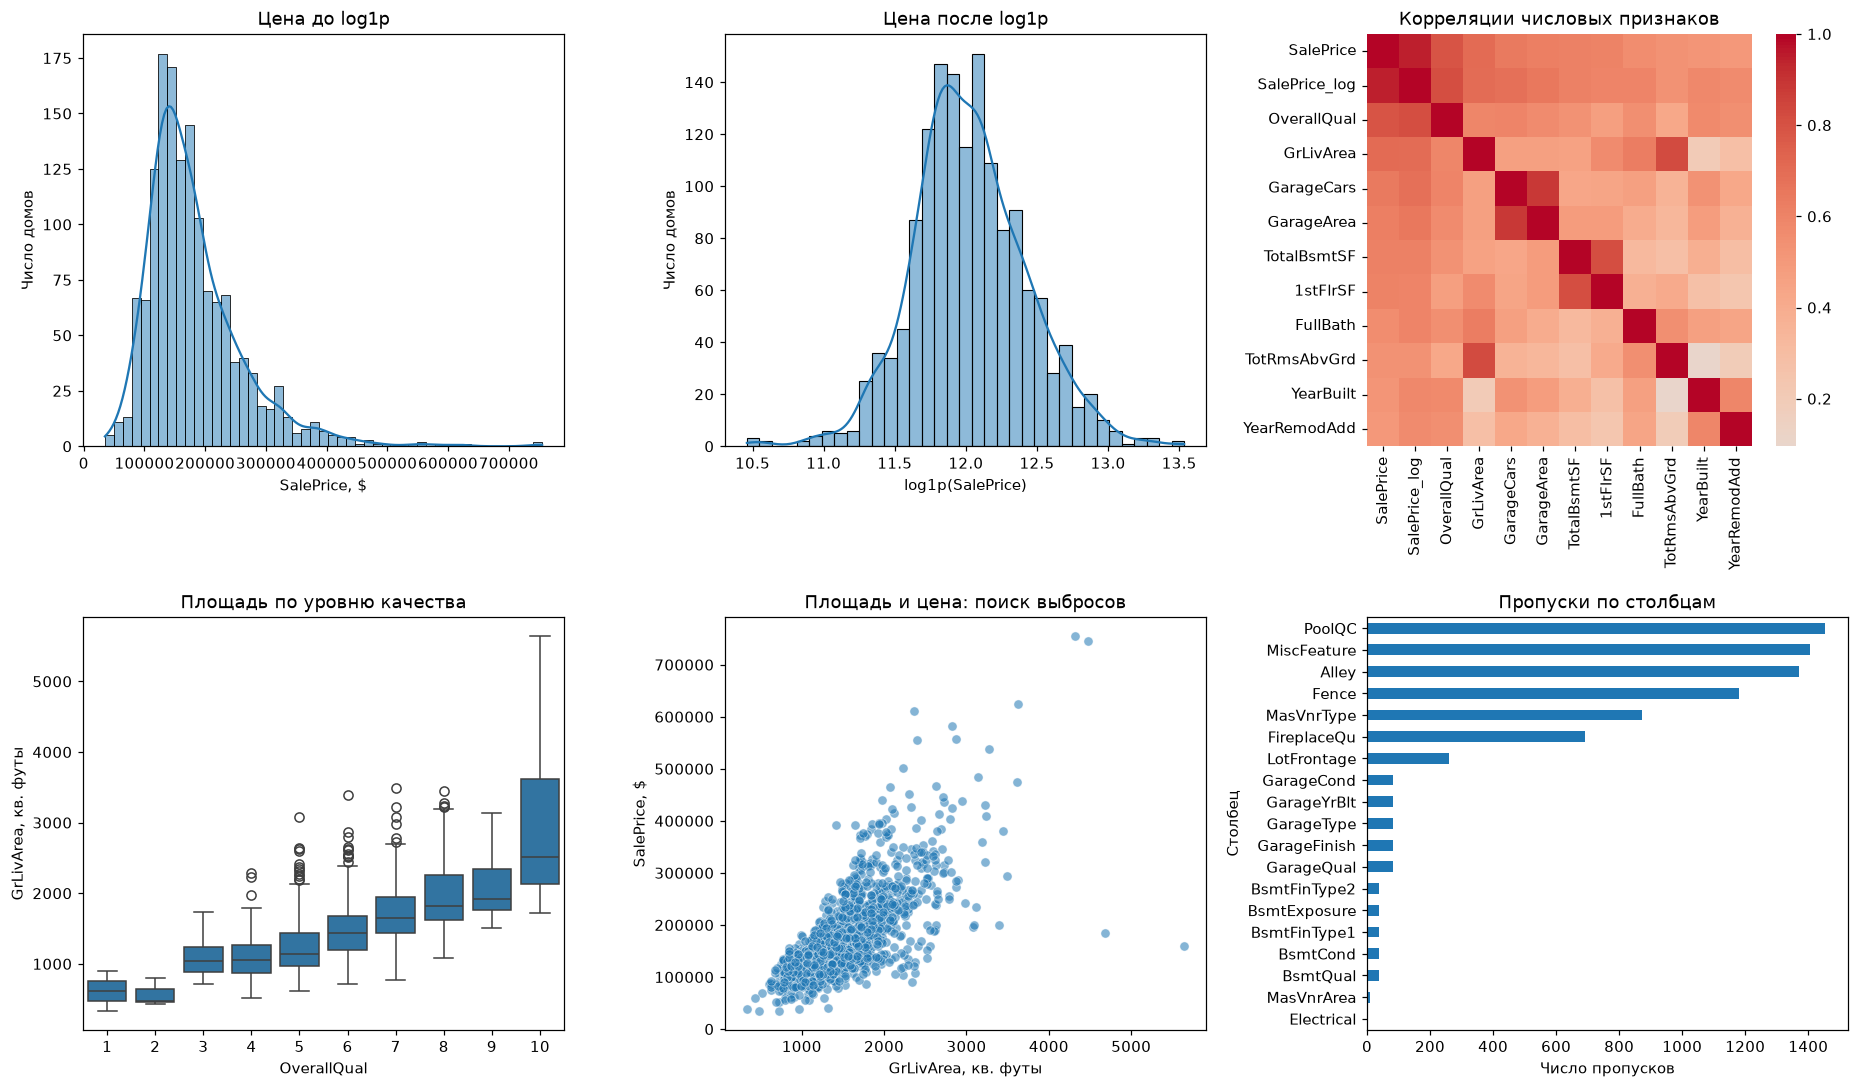

In [3]:
# Строим требуемые распределения, связи и пропуски на одной сетке.
fig, axes = plt.subplots(2, 3, figsize=(17, 10))
sns.histplot(train_df.SalePrice, kde=True, ax=axes[0, 0])
axes[0, 0].set(title='Цена до log1p', xlabel='SalePrice, $', ylabel='Число домов')
sns.histplot(train_df.SalePrice_log, kde=True, ax=axes[0, 1])
axes[0, 1].set(title='Цена после log1p', xlabel='log1p(SalePrice)', ylabel='Число домов')
top_corr = train_df.select_dtypes(include='number').corr()['SalePrice'].abs().nlargest(12).index
sns.heatmap(train_df[top_corr].corr(), cmap='coolwarm', center=0, ax=axes[0, 2])
axes[0, 2].set(title='Корреляции числовых признаков')
sns.boxplot(data=train_df, x='OverallQual', y='GrLivArea', ax=axes[1, 0])
axes[1, 0].set(title='Площадь по уровню качества', xlabel='OverallQual', ylabel='GrLivArea, кв. футы')
sns.scatterplot(data=train_df, x='GrLivArea', y='SalePrice', alpha=.55, ax=axes[1, 1])
axes[1, 1].set(title='Площадь и цена: поиск выбросов', xlabel='GrLivArea, кв. футы', ylabel='SalePrice, $')
missing[missing > 0].sort_values().plot.barh(ax=axes[1, 2])
axes[1, 2].set(title='Пропуски по столбцам', xlabel='Число пропусков', ylabel='Столбец')
fig.tight_layout()
fig.savefig(EXAMPLE_DIR / 'eda_plots.png', dpi=150)


In [4]:
# IQR отмечает крупные дома; доменное условие отделяет подозрительные сделки.
q1, q3 = train_df.GrLivArea.quantile([.25, .75])
iqr_limit = q3 + 1.5 * (q3 - q1)
iqr_flag = train_df.GrLivArea > iqr_limit
domain_flag = (train_df.GrLivArea > 4000) & (train_df.SalePrice < 300000)
print(f'IQR upper: {iqr_limit:.1f}; IQR flagged: {iqr_flag.sum()}; domain outliers: {domain_flag.sum()}')
print('Skew log target:', round(train_df.SalePrice_log.skew(), 3))


IQR upper: 2747.6; IQR flagged: 31; domain outliers: 2
Skew log target: 0.121


### Наблюдения по EDA

После `log1p` асимметрия цены снижается с 1,883 до **0,121**. На графиках цена связана с качеством и жилой площадью; площади и размеры гаража заметно коррелируют между собой. Метод IQR помечает **31** дом с `GrLivArea` выше 2747,6 кв. фута, но среди них есть правдоподобные большие дорогие дома. Доменное условие `GrLivArea > 4000` и `SalePrice < $300 000` выделяет **2** особенно необычные сделки.

### Обоснование обработки пропусков

В исходном обучении пропуски есть в **19** столбцах. Пустые `PoolQC`, `GarageType`, характеристики подвала и другие поля отсутствующих объектов получают категорию `None`, связанные количественные признаки — 0. Для `LotFrontage` используется медиана своего `Neighborhood`, а при отсутствии такой медианы — общая обучающая медиана. Остальные числа заполняются обучающей медианой, категории — обучающей модой. Порядковые оценки качества кодируются ручной шкалой, номинальные категории — one-hot. Правила оцениваются на обучающей части, чтобы проверка оставалась независимой.

In [5]:
# Фиксируем группы осмысленных пропусков и шкалы качества.
NONE_CATS = ['Alley', 'MasVnrType', 'BsmtQual', 'BsmtCond', 'BsmtExposure',
             'BsmtFinType1', 'BsmtFinType2', 'FireplaceQu', 'GarageType',
             'GarageFinish', 'GarageQual', 'GarageCond', 'PoolQC', 'Fence', 'MiscFeature']
ZERO_NUMS = ['MasVnrArea', 'BsmtFinSF1', 'BsmtFinSF2', 'BsmtUnfSF', 'TotalBsmtSF',
             'BsmtFullBath', 'BsmtHalfBath', 'GarageYrBlt', 'GarageCars', 'GarageArea']
QUALITY = {'None': 0, 'Po': 1, 'Fa': 2, 'TA': 3, 'Gd': 4, 'Ex': 5}
ORDINAL_MAPS = {c: QUALITY for c in ['ExterQual', 'ExterCond', 'BsmtQual', 'BsmtCond',
                'HeatingQC', 'KitchenQual', 'FireplaceQu', 'GarageQual', 'GarageCond', 'PoolQC']}
ORDINAL_MAPS.update({'BsmtExposure': {'None': 0, 'No': 1, 'Mn': 2, 'Av': 3, 'Gd': 4},
                     'BsmtFinType1': {'None': 0, 'Unf': 1, 'LwQ': 2, 'Rec': 3, 'BLQ': 4, 'ALQ': 5, 'GLQ': 6},
                     'BsmtFinType2': {'None': 0, 'Unf': 1, 'LwQ': 2, 'Rec': 3, 'BLQ': 4, 'ALQ': 5, 'GLQ': 6},
                     'GarageFinish': {'None': 0, 'Unf': 1, 'RFn': 2, 'Fin': 3}})

# Сначала разделяем исходные строки, затем исключаем два аномальных дома из обучения.
raw_train, raw_valid = train_test_split(train_df, test_size=.2, random_state=42)
train_outliers = (raw_train.GrLivArea > 4000) & (raw_train.SalePrice < 300000)
raw_train = raw_train.loc[~train_outliers].copy()
print('Обучение:', len(raw_train), 'Проверка:', len(raw_valid), 'Исключено из обучения:', int(train_outliers.sum()))


Обучение: 1166 Проверка: 292 Исключено из обучения: 2


In [6]:
# Параметры заполнения оцениваем исключительно на обучающих строках.
def fit_preprocessor(frame):
    base = frame.drop(columns=['Id', 'SalePrice', 'SalePrice_log'], errors='ignore').copy()
    base['MSSubClass'] = base.MSSubClass.astype(str)
    num_cols = list(base.select_dtypes(include='number').columns)
    cat_cols = list(base.select_dtypes(exclude='number').columns)
    return {
        'base_cols': list(base.columns), 'num_cols': num_cols, 'cat_cols': cat_cols,
        'frontage_by_neighborhood': base.groupby('Neighborhood').LotFrontage.median().to_dict(),
        'frontage_global': float(base.LotFrontage.median()),
        'numeric_medians': {c: float(base[c].median()) for c in num_cols if c not in ZERO_NUMS + ['LotFrontage']},
        'categorical_modes': {c: str(base[c].mode(dropna=True).iloc[0]) for c in cat_cols if c not in NONE_CATS},
    }

# Одинаковая функция применяет сохранённые правила к обучению, проверке и новым домам.
def transform_raw(frame, prep, feature_cols=None):
    x = frame.reindex(columns=prep['base_cols']).copy()
    x['MSSubClass'] = x.MSSubClass.astype(str)
    for col in NONE_CATS:
        x[col] = x[col].fillna('None')
    for col in ZERO_NUMS:
        x[col] = x[col].fillna(0)
    frontage = x['Neighborhood'].map(prep['frontage_by_neighborhood'])
    x['LotFrontage'] = x.LotFrontage.fillna(frontage).fillna(prep['frontage_global'])
    for col, value in prep['numeric_medians'].items():
        x[col] = x[col].fillna(value)
    for col, value in prep['categorical_modes'].items():
        x[col] = x[col].fillna(value)
    for col, mapping in ORDINAL_MAPS.items():
        x[col] = x[col].map(mapping).fillna(0).astype(float)
    x['TotalSF'] = x.TotalBsmtSF + x['1stFlrSF'] + x['2ndFlrSF']
    x['TotalBath'] = x.FullBath + .5*x.HalfBath + x.BsmtFullBath + .5*x.BsmtHalfBath
    x['TotalPorch'] = x[['WoodDeckSF', 'OpenPorchSF', 'EnclosedPorch', '3SsnPorch', 'ScreenPorch']].sum(axis=1)
    x['HouseAge'] = x.YrSold - x.YearBuilt
    x['RemodAge'] = x.YrSold - x.YearRemodAdd
    x['HasPool'] = (x.PoolArea > 0).astype(int)
    x['HasGarage'] = (x.GarageCars > 0).astype(int)
    x['Has2ndFloor'] = (x['2ndFlrSF'] > 0).astype(int)
    x['HasFireplace'] = (x.Fireplaces > 0).astype(int)
    x['OverallQual_TotalSF'] = x.OverallQual * x.TotalSF
    x = pd.get_dummies(x, columns=list(x.select_dtypes(exclude='number').columns), dtype=float)
    if feature_cols is not None:
        x = x.reindex(columns=feature_cols, fill_value=0)
    return x.astype(float)

# Проверяем, что ни один признак не остался с NaN и колонки совпадают.
preprocessor = fit_preprocessor(raw_train)
X_train = transform_raw(raw_train, preprocessor)
feature_cols = list(X_train.columns)
X_valid = transform_raw(raw_valid, preprocessor, feature_cols)
X_competition = transform_raw(test_df, preprocessor, feature_cols)
y_train, y_valid = raw_train.SalePrice_log, raw_valid.SalePrice_log
assert not X_train.isna().any().any() and not X_valid.isna().any().any()
assert list(X_train.columns) == list(X_valid.columns) == list(X_competition.columns)
print('Признаков после кодирования:', len(feature_cols), 'NaN:', int(X_train.isna().sum().sum()))
print('Feature Engineering:', [c for c in ['TotalSF', 'TotalBath', 'TotalPorch', 'HouseAge', 'RemodAge', 'HasPool', 'HasGarage', 'Has2ndFloor', 'HasFireplace', 'OverallQual_TotalSF'] if c in feature_cols])


Признаков после кодирования: 264 NaN: 0
Feature Engineering: ['TotalSF', 'TotalBath', 'TotalPorch', 'HouseAge', 'RemodAge', 'HasPool', 'HasGarage', 'Has2ndFloor', 'HasFireplace', 'OverallQual_TotalSF']


### Итог предобработки

После кодирования получены **264 признака без NaN**. `Id`, `SalePrice` и `SalePrice_log` исключены из матрицы признаков. Добавлены `TotalSF`, `TotalBath`, `TotalPorch`, два возраста дома, четыре бинарных индикатора и взаимодействие `OverallQual_TotalSF`. Столбцы отложенной выборки и Kaggle `test.csv` выровнены по обучению; масштабирование обучается только на `X_train`.

## 6. Построение и обучение моделей

Linear Regression задаёт базу без штрафа. Ridge ограничивает коэффициенты при коррелирующих площадях; Lasso может удалить слабые признаки; ElasticNet сочетает оба подхода. Для регуляризованных моделей выбираем параметры по пяти блокам кросс-валидации на обучающей части с метрикой RMSE в логарифмической шкале. Время ниже включает поиск параметров, поэтому оно больше времени одного `fit`.

In [7]:
# Масштабируем числовую матрицу после деления на обучение и проверку.
scaler = StandardScaler()
X_train_scaled = scaler.fit_transform(X_train)
X_valid_scaled = scaler.transform(X_valid)
cv = KFold(n_splits=5, shuffle=True, random_state=42)
models, train_times, cv_scores, best_params = {}, {}, {}, {}

# Базовая модель не имеет подбираемых гиперпараметров.
start = time.perf_counter()
models['Linear Regression'] = LinearRegression().fit(X_train_scaled, y_train)
train_times['Linear Regression'] = time.perf_counter() - start
best_params['Linear Regression'] = {}
cv_scores['Linear Regression'] = np.nan

# Подбор идёт только по обучающей части; отложенная часть остаётся нетронутой.
search_spaces = {
    'Ridge': (Ridge(), {'alpha': [1.0, 10.0, 100.0]}),
    'Lasso': (Lasso(max_iter=30000, random_state=42), {'alpha': [.0002, .0005, .001, .002]}),
    'ElasticNet': (ElasticNet(max_iter=30000, random_state=42),
                   {'alpha': [.0005, .001, .002], 'l1_ratio': [.3, .5, .8]})
}
for name, (estimator, grid) in search_spaces.items():
    search = GridSearchCV(estimator, grid, cv=cv, scoring='neg_root_mean_squared_error', n_jobs=1)
    start = time.perf_counter()
    search.fit(X_train_scaled, y_train)
    train_times[name] = time.perf_counter() - start
    models[name] = search.best_estimator_
    best_params[name] = search.best_params_
    cv_scores[name] = -search.best_score_
    print(name, best_params[name], 'CV RMSE(log)=', round(cv_scores[name], 5),
          'search time(s)=', round(train_times[name], 3))
print('Linear Regression training time(s)=', round(train_times['Linear Regression'], 3))


Ridge {'alpha': 100.0} CV RMSE(log)= 0.11811 search time(s)= 0.464
Lasso {'alpha': 0.002} CV RMSE(log)= 0.11281 search time(s)= 8.847
ElasticNet {'alpha': 0.002, 'l1_ratio': 0.8} CV RMSE(log)= 0.11409 search time(s)= 14.828
Linear Regression training time(s)= 0.152


### Результаты обучения

| Модель | Параметры | Масштабирование | Время обучения и подбора, с |
|---|---|:---:|---:|
| Linear Regression | без регуляризации | да | 0,152 |
| Ridge | `alpha=100` | да | 0,464 |
| Lasso | `alpha=0.002` | да | 8,847 |
| ElasticNet | `alpha=0.002`, `l1_ratio=0.8` | да | 14,828 |

Время для регуляризованных моделей включает `GridSearchCV` с пятью блоками. Все модели используют одинаковую обучающую и отложенную части; параметры выбираются без просмотра отложенных цен. Lasso показывает наименьший CV RMSE (log) в этом запуске — **0,11281**.

## 7. Оценка качества

Отложенная выборка содержит размеченные дома из `train.csv`; Kaggle `test.csv` без целевой цены для оценки качества не подходит. Считаем RMSE, MAE и R² в log-шкале, а также RMSE и MAE в долларах. Лучшую модель выбираем по CV RMSE, чтобы не выбирать её на отложенной выборке.

In [8]:
# Возвращаем прогноз из логарифмов к цене для метрик в долларах.
def evaluate_model(model, x_scaled, y_log):
    predicted_log = model.predict(x_scaled)
    actual_dollars, predicted_dollars = np.expm1(y_log), np.expm1(predicted_log)
    return {'rmse_log': float(np.sqrt(mean_squared_error(y_log, predicted_log))),
            'mae_log': float(mean_absolute_error(y_log, predicted_log)),
            'r2_log': float(r2_score(y_log, predicted_log)),
            'rmse_dollars': float(np.sqrt(mean_squared_error(actual_dollars, predicted_dollars))),
            'mae_dollars': float(mean_absolute_error(actual_dollars, predicted_dollars))}

# Сравниваем все модели на одной отложенной части.
metrics = {name: evaluate_model(model, X_valid_scaled, y_valid) for name, model in models.items()}
best_name = min(('Ridge', 'Lasso', 'ElasticNet'), key=lambda name: cv_scores[name])
best_model = models[best_name]
metrics_table = pd.DataFrame(metrics).T
print(metrics_table.round(5).to_string())
print('Лучшая по CV:', best_name, 'R²(log) на проверке:', round(metrics[best_name]['r2_log'], 4))


                   rmse_log  mae_log   r2_log  rmse_dollars  mae_dollars
Linear Regression   0.12426  0.08809  0.91725   22887.04661  15260.40222
Ridge               0.12300  0.08610  0.91892   22361.74745  14903.63630
Lasso               0.11994  0.08227  0.92291   21859.46598  14282.22714
ElasticNet          0.12063  0.08305  0.92202   21964.96488  14402.00616
Лучшая по CV: Lasso R²(log) на проверке: 0.9229


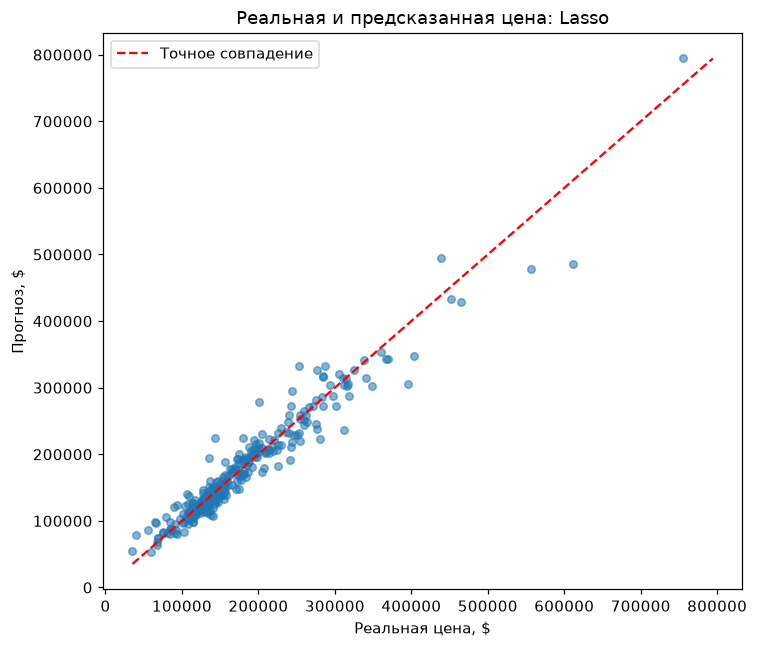

In [9]:
# Сопоставляем реальные и предсказанные цены лучшей модели.
y_true_dollars = np.expm1(y_valid.to_numpy())
y_pred_dollars = np.expm1(best_model.predict(X_valid_scaled))
fig, ax = plt.subplots(figsize=(7, 6))
ax.scatter(y_true_dollars, y_pred_dollars, alpha=.55, s=24)
limits = [min(y_true_dollars.min(), y_pred_dollars.min()), max(y_true_dollars.max(), y_pred_dollars.max())]
ax.plot(limits, limits, 'r--', label='Точное совпадение')
ax.set(title=f'Реальная и предсказанная цена: {best_name}', xlabel='Реальная цена, $', ylabel='Прогноз, $')
ax.legend()
fig.tight_layout()
fig.savefig(EXAMPLE_DIR / 'predictions_scatter.png', dpi=150)


Среднее остатков: $900; стандартное отклонение: $21,841
Медиана абсолютной ошибки: $9,098


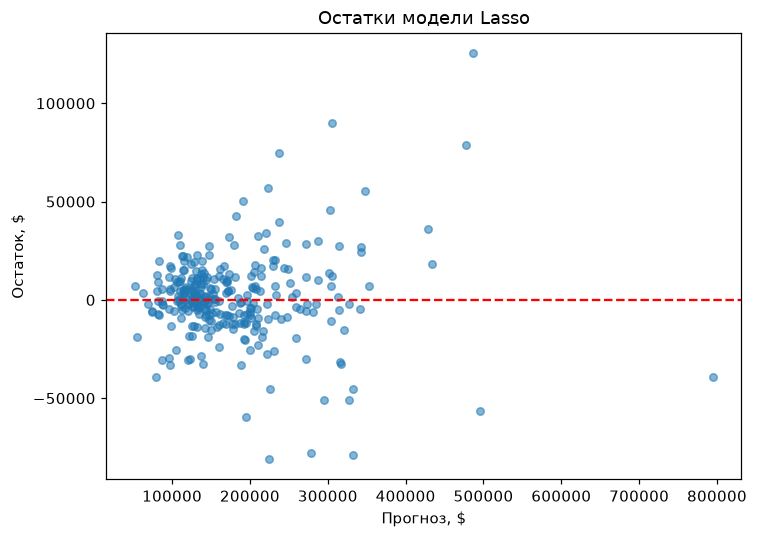

In [10]:
# Остатки считаются как истинная цена минус прогноз в долларах.
residuals = y_true_dollars - y_pred_dollars
fig, ax = plt.subplots(figsize=(7, 5))
ax.scatter(y_pred_dollars, residuals, alpha=.55, s=24)
ax.axhline(0, color='red', linestyle='--')
ax.set(title=f'Остатки модели {best_name}', xlabel='Прогноз, $', ylabel='Остаток, $')
fig.tight_layout()
fig.savefig(EXAMPLE_DIR / 'residuals.png', dpi=150)
print('Среднее остатков: ${:,.0f}; стандартное отклонение: ${:,.0f}'.format(residuals.mean(), residuals.std()))
print('Медиана абсолютной ошибки: ${:,.0f}'.format(np.median(np.abs(residuals))))


### Результаты и анализ ошибок

| Модель | RMSE (log) | MAE (log) | R² (log) | RMSE ($) |
|---|---:|---:|---:|---:|
| Linear Regression | 0,1243 | 0,0881 | 0,9173 | 22 887 |
| Ridge | 0,1230 | 0,0861 | 0,9189 | 22 362 |
| **Lasso** | **0,1199** | **0,0823** | **0,9229** | **21 859** |
| ElasticNet | 0,1206 | 0,0831 | 0,9220 | 21 965 |

**Лучшая по CV — Lasso.** На отложенной выборке она достигает R² = **0,9229** в логарифмической шкале и наименьшего RMSE в долларах среди четырёх моделей. На графике большинство точек близко к диагонали, но среди дорогих домов есть заметные ошибки. Средний остаток равен **+$900**, стандартное отклонение — **$21 841**, медиана абсолютного остатка — **$9 098**. Положительный средний остаток означает небольшое среднее занижение прогноза в долларах; это не делает каждое отдельное предсказание заниженным.

## 8. Интерпретация результатов

Коэффициенты относятся к стандартизованным признакам и к `log1p(SalePrice)`. Их знак описывает связь при фиксированных остальных столбцах; коррелирующие площади и dummy-категории делают причинную трактовку и перевод отдельного коэффициента в точную «надбавку к цене» некорректными.

Ridge: положительные
 GrLivArea              0.0365
OverallQual            0.0355
OverallQual_TotalSF    0.0353
OverallCond            0.0340
TotalSF                0.0322
1stFlrSF               0.0255
YearBuilt              0.0208
GarageArea             0.0206
BsmtFinSF1             0.0198
2ndFlrSF               0.0195
Ridge: отрицательные
 HouseAge                -0.0208
MSZoning_C (all)        -0.0172
MSSubClass_160          -0.0145
MSSubClass_30           -0.0133
Functional_Maj2         -0.0132
Neighborhood_MeadowV    -0.0130
SaleCondition_Abnorml   -0.0114
Exterior1st_BrkComm     -0.0108
Functional_Sev          -0.0103
Heating_Grav            -0.0099


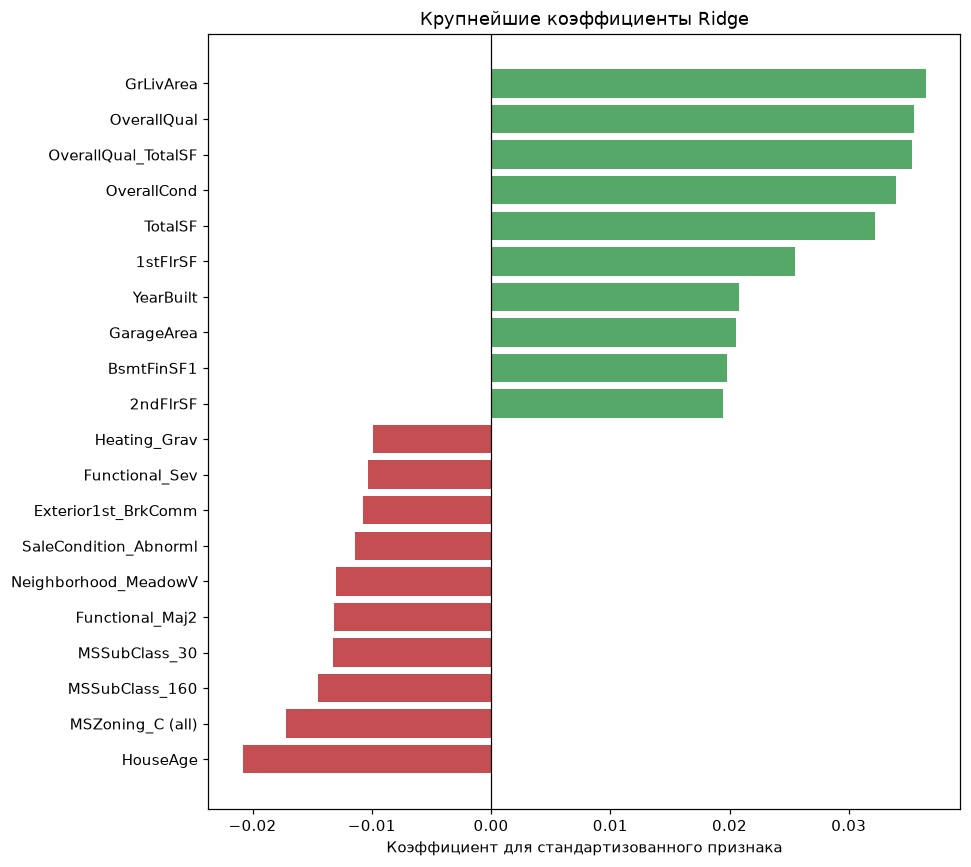

In [11]:
# Показываем самые сильные положительные и отрицательные веса Ridge.
ridge_coef = pd.Series(models['Ridge'].coef_, index=feature_cols)
top_positive = ridge_coef.nlargest(10)
top_negative = ridge_coef.nsmallest(10)
print('Ridge: положительные\n', top_positive.round(4).to_string())
print('Ridge: отрицательные\n', top_negative.round(4).to_string())
fig, ax = plt.subplots(figsize=(9, 8))
selected = pd.concat([top_negative, top_positive]).sort_values()
ax.barh(selected.index, selected.values, color=['#c44e52' if value < 0 else '#55a868' for value in selected])
ax.axvline(0, color='black', linewidth=.8)
ax.set(title='Крупнейшие коэффициенты Ridge', xlabel='Коэффициент для стандартизованного признака')
fig.tight_layout()


In [12]:
# Нулевые коэффициенты Lasso показывают фактический отбор столбцов.
lasso_coef = pd.Series(models['Lasso'].coef_, index=feature_cols)
n_zero = int(np.isclose(lasso_coef, 0, atol=1e-10).sum())
n_total = len(lasso_coef)
print(f'Lasso обнулил {n_zero} из {n_total} признаков; осталось {n_total - n_zero}.')
print('Сильнейшие ненулевые:\n', lasso_coef[~np.isclose(lasso_coef, 0, atol=1e-10)].abs().nlargest(15).round(4).to_string())
print('Корреляция GarageCars и GarageArea:', round(train_df[['GarageCars', 'GarageArea']].corr().iloc[0, 1], 3))
pool_prices = train_df.groupby(train_df.PoolArea.gt(0)).SalePrice.agg(['count', 'mean'])
print('Цена по наличию бассейна (описательно, без поправок):\n', pool_prices.round(0).to_string())


Lasso обнулил 133 из 264 признаков; осталось 131.
Сильнейшие ненулевые:
 GrLivArea               0.0721
TotalSF                 0.0506
OverallQual             0.0484
HouseAge                0.0427
OverallQual_TotalSF     0.0406
OverallCond             0.0381
BsmtFinSF1              0.0274
GarageArea              0.0195
Neighborhood_Crawfor    0.0181
MSSubClass_160          0.0157
MSZoning_RM             0.0152
RemodAge                0.0152
TotalBath               0.0151
MSZoning_C (all)        0.0151
Foundation_PConc        0.0151
Корреляция GarageCars и GarageArea: 0.882
Цена по наличию бассейна (описательно, без поправок):
           count      mean
PoolArea                 
False      1453  180405.0
True          7  288139.0


### Коэффициенты и бизнес-инсайты

Наиболее крупные **положительные** коэффициенты Ridge: `GrLivArea` (0,0365), `OverallQual` (0,0355), `OverallQual_TotalSF` (0,0353), `OverallCond` (0,0340) и `TotalSF` (0,0322). Крупные **отрицательные**: `HouseAge` (−0,0208), `MSZoning_C (all)` (−0,0172), `MSSubClass_160` (−0,0145), `MSSubClass_30` (−0,0133) и `Functional_Maj2` (−0,0132). Это коэффициенты для стандартизованных признаков и логарифма цены, поэтому их нельзя напрямую читать как доллары или причинное влияние.

Lasso обнулила **133 из 264** коэффициентов: остался 131 признак. Площадь, качество и возраст дома помогают модели различать цены. Корреляция `GarageCars` и `GarageArea` равна **0,882**, что затрудняет интерпретацию каждого коэффициента отдельно. Дома с бассейном в исходной выборке имеют более высокую среднюю цену ($288 139 против $180 405), но их всего **7** против **1453** без бассейна; считать эту разницу ценой бассейна нельзя.

## 9. Функция предсказания

Функция принимает **исходные** поля дома, применяет те же правила заполнения, инженерии признаков, кодирования и масштабирования, что использовались при обучении. Для демонстрации выбраны пять реальных строк `test.csv` с разными сочетаниями качества и площади. Так сохраняется согласованность всех характеристик; в этом датасете продажи относятся к 2006–2010 годам, поэтому придуманные годы постройки 2015/2018 из иллюстрации задания не используются.

In [13]:
# Дополнительный аргумент хранит правила обработки сырых домов.
def predict_price(house_data, model, scaler, feature_cols, preprocessor=preprocessor):
    """Возвращает прогноз цены в долларах для словаря исходных полей дома."""
    x_raw = pd.DataFrame([house_data])
    x_features = transform_raw(x_raw, preprocessor, feature_cols)
    x_scaled = scaler.transform(x_features)
    return float(np.expm1(model.predict(x_scaled)[0]))

# Берём разнообразные реальные профили без известных целевых цен.
targets = [(9, 2800), (6, 1500), (4, 900), (10, 4000), (5, 1200)]
available = test_df.copy()
profiles = []
for quality, area in targets:
    distance = (available.OverallQual - quality).abs()*600 + (available.GrLivArea - area).abs()
    idx = distance.idxmin()
    profiles.append(available.loc[idx].to_dict())
    available = available.drop(index=idx)

# Выводим профиль и прогноз каждой из обязательных моделей.
for i, house in enumerate(profiles, 1):
    description = {key: house[key] for key in ['Id', 'OverallQual', 'GrLivArea', 'YearBuilt', 'GarageCars', 'FullBath', 'HalfBath']}
    predictions = {name: round(predict_price(house, model, scaler, feature_cols)) for name, model in models.items()}
    print(f'Дом {i}: {description}; прогнозы ($): {predictions}')


Дом 1: {'Id': 2628, 'OverallQual': 9, 'GrLivArea': 2798, 'YearBuilt': 2005, 'GarageCars': 3.0, 'FullBath': 3, 'HalfBath': 1}; прогнозы ($): {'Linear Regression': 497758, 'Ridge': 497593, 'Lasso': 481056, 'ElasticNet': 483488}
Дом 2: {'Id': 2370, 'OverallQual': 6, 'GrLivArea': 1501, 'YearBuilt': 1999, 'GarageCars': 2.0, 'FullBath': 2, 'HalfBath': 1}; прогнозы ($): {'Linear Regression': 168151, 'Ridge': 170007, 'Lasso': 166064, 'ElasticNet': 166739}
Дом 3: {'Id': 2121, 'OverallQual': 4, 'GrLivArea': 896, 'YearBuilt': 1946, 'GarageCars': 1.0, 'FullBath': 1, 'HalfBath': 0}; прогнозы ($): {'Linear Regression': 90203, 'Ridge': 88306, 'Lasso': 95019, 'ElasticNet': 94694}
Дом 4: {'Id': 2629, 'OverallQual': 10, 'GrLivArea': 3390, 'YearBuilt': 2006, 'GarageCars': 3.0, 'FullBath': 3, 'HalfBath': 1}; прогнозы ($): {'Linear Regression': 599086, 'Ridge': 578533, 'Lasso': 570804, 'ElasticNet': 574190}
Дом 5: {'Id': 1781, 'OverallQual': 5, 'GrLivArea': 1200, 'YearBuilt': 1950, 'GarageCars': 1.0, 'Full

### Проверка функции на пяти домах

Для каждого профиля код выше выводит характеристики дома и прогнозы **всех четырёх моделей**. Ниже приведён прогноз лучшей модели Lasso для быстрой проверки диапазона:

| Дом | `OverallQual` | `GrLivArea`, кв. футы | Прогноз Lasso, $ |
|---:|---:|---:|---:|
| 1 | 9 | 2798 | 481 056 |
| 2 | 6 | 1501 | 166 064 |
| 3 | 4 | 896 | 95 019 |
| 4 | 10 | 3390 | 570 804 |
| 5 | 5 | 1200 | 120 811 |

Все пять домов взяты из `test.csv`, где `SalePrice` неизвестна; эти числа нельзя использовать для расчёта ошибки. Редкие сочетания свойств и дорогие дома могут прогнозироваться менее устойчиво.

## 10. Сохранение модели и вспомогательных объектов

Четыре обученные модели сохранены через `joblib` как `lr_model.pkl`, `ridge_model.pkl`, `lasso_model.pkl` и `enet_model.pkl`; лучшая по CV продублирована в `best_model.pkl`. Для повторного прогноза по исходным полям дома также сохранены `scaler.pkl` и `preprocessor.pkl`. Порядок 264 признаков записан в `feature_cols.json`, метрики, время подбора и параметры моделей — в `metrics.json`.

Все файлы размещаются в `module-2-house-prices/models/`. Артефакты опубликованы в ветке main и проверены по raw-ссылкам в разделе 11.

In [14]:
# Записываем модели и все объекты, необходимые для повторного инференса.
filenames = {'Linear Regression': 'lr_model.pkl', 'Ridge': 'ridge_model.pkl',
             'Lasso': 'lasso_model.pkl', 'ElasticNet': 'enet_model.pkl'}
for name, filename in filenames.items():
    joblib.dump(models[name], MODEL_DIR / filename)
joblib.dump(best_model, MODEL_DIR / 'best_model.pkl')
joblib.dump(scaler, MODEL_DIR / 'scaler.pkl')
joblib.dump(preprocessor, MODEL_DIR / 'preprocessor.pkl')

# Метаданные сохраняем в обычном JSON для просмотра без Python.
(MODEL_DIR / 'feature_cols.json').write_text(json.dumps(feature_cols, ensure_ascii=False, indent=2), encoding='utf-8')
report = {'selection_metric': 'five-fold CV RMSE on log1p(SalePrice)', 'best_model': best_name,
          'models': {name: {**values, 'train_time_sec': float(train_times[name]),
                            'cv_rmse_log': None if np.isnan(cv_scores[name]) else float(cv_scores[name]),
                            'parameters': best_params[name]} for name, values in metrics.items()},
          'lasso_features_selected': int(n_total - n_zero), 'lasso_features_dropped': int(n_zero),
          'training_rows': len(raw_train), 'validation_rows': len(raw_valid),
          'removed_training_outliers': int(train_outliers.sum()), 'feature_count': len(feature_cols)}
(MODEL_DIR / 'metrics.json').write_text(json.dumps(report, ensure_ascii=False, indent=2), encoding='utf-8')
print('Сохранены:', ', '.join(sorted(path.name for path in MODEL_DIR.iterdir())))


Сохранены: best_model.pkl, enet_model.pkl, feature_cols.json, lasso_model.pkl, lr_model.pkl, metrics.json, preprocessor.pkl, ridge_model.pkl, scaler.pkl


### Итог сохранения

В папке `models/` сохранены все четыре модели, `best_model.pkl`, `scaler.pkl`, `preprocessor.pkl`, `feature_cols.json` и `metrics.json`. Файлы присутствуют локально; проверка повторной загрузки приведена в следующем разделе.


## 11. Загрузка модели из репозитория и быстрый инференс

Опубликованные артефакты читаются по адресу `https://raw.githubusercontent.com/VolodinaAlexandra/ml-course-volodina/main/module-2-house-prices/`. Код загружает модель, scaler, параметры обработки исходных полей и список признаков, проверяет HTTP-статус и сравнивает три прогноза с локальной моделью. Отдельная локальная загрузка выше подтверждает, что сохранённые файлы работают без переобучения.


In [15]:
# Локальная загрузка имитирует повторный запуск без обучения.
loaded_model = joblib.load(MODEL_DIR / 'best_model.pkl')
loaded_scaler = joblib.load(MODEL_DIR / 'scaler.pkl')
loaded_preprocessor = joblib.load(MODEL_DIR / 'preprocessor.pkl')
loaded_features = json.loads((MODEL_DIR / 'feature_cols.json').read_text(encoding='utf-8'))
for i, house in enumerate(profiles[:3], 1):
    original = predict_price(house, best_model, scaler, feature_cols)
    restored = predict_price(house, loaded_model, loaded_scaler, loaded_features, loaded_preprocessor)
    assert np.isclose(original, restored, rtol=0, atol=1e-8)
    print(f'Дом {i}: исходный ${original:,.2f}; загруженный ${restored:,.2f}; совпали')


Дом 1: исходный $481,055.60; загруженный $481,055.60; совпали
Дом 2: исходный $166,064.47; загруженный $166,064.47; совпали
Дом 3: исходный $95,019.15; загруженный $95,019.15; совпали


In [16]:
# Публикация выполнена; загружаем четыре артефакта по raw-ссылкам.
BASE_URL = 'https://raw.githubusercontent.com/VolodinaAlexandra/ml-course-volodina/main/module-2-house-prices'

def load_published_artifacts(base_url=BASE_URL):
    """Скачивает модель и подготовку из опубликованной ветки main."""
    import requests
    def download(relative_path):
        response = requests.get(f'{base_url}/{relative_path}', timeout=30)
        response.raise_for_status()
        return response.content
    model = joblib.load(BytesIO(download('models/best_model.pkl')))
    scale = joblib.load(BytesIO(download('models/scaler.pkl')))
    prep = joblib.load(BytesIO(download('models/preprocessor.pkl')))
    features = json.loads(download('models/feature_cols.json').decode('utf-8'))
    return model, scale, features, prep

# Сверяем порядок признаков и три прогноза с локально обученной моделью.
remote_model, remote_scaler, remote_features, remote_preprocessor = load_published_artifacts()
assert remote_features == feature_cols
for i, house in enumerate(profiles[:3], 1):
    local_price = predict_price(house, best_model, scaler, feature_cols)
    remote_price = predict_price(house, remote_model, remote_scaler, remote_features, remote_preprocessor)
    assert np.isclose(local_price, remote_price, rtol=0, atol=1e-8)
    print(f'GitHub raw, дом {i}: ${remote_price:,.2f}; прогноз совпал')


GitHub raw, дом 1: $481,055.60; прогноз совпал
GitHub raw, дом 2: $166,064.47; прогноз совпал
GitHub raw, дом 3: $95,019.15; прогноз совпал


### Проверка загрузки

Модель, scaler, параметры предобработки и порядок признаков загружены из опубликованной ветки `main` по raw-ссылкам. Для трёх домов удалённые прогнозы совпали с локальными до цента: **$481 055,60**, **$166 064,47** и **$95 019,15**. Так проверена загрузка из GitHub без переобучения.


## 12. Выводы

### Что получилось

Проведён EDA 1460 размеченных домов, обработаны пропуски и два доменных выброса в обучении, созданы новые признаки и сравнены четыре модели. Лучшая по CV — **Lasso** (`alpha=0.002`): на отложенной выборке R² (log) = **0,9229**, RMSE (log) = **0,1199**, RMSE = **$21 859**. В этом выполнении подбор Lasso занял **8,847 с**. Реализованы пять прогнозов для домов из `test.csv` и локальная проверка повторной загрузки модели. EDA показал правую асимметрию цены, связь цены с площадью и качеством, а также корреляцию близких признаков.

### Трудности и ограничения

Пропуски встречаются в **19** столбцах и имеют разный смысл. Логарифмирование снизило асимметрию цены с **1,883** до **0,121**, но не устранило редкие случаи и ошибки для дорогих домов. Мультиколлинеарность, например корреляция `GarageCars` и `GarageArea` **0,882**, усложняет трактовку отдельных коэффициентов. В `test.csv` нет истинных цен. Загрузка из опубликованной ветки `main` проверена на трёх домах; прогнозы совпали с локальными.

### Возможные улучшения

1. Проверить target encoding `Neighborhood` внутри кросс-валидации без утечки.
2. Сравнить градиентный бустинг и случайный лес на той же отложенной выборке.
3. Провести RFE или permutation importance для отбора признаков.
4. Расширить поиск параметров регуляризации или применить Optuna.
5. Исследовать stacking Ridge, Lasso и бустинга.
6. Проверить устойчивость к выбросам повторной кросс-валидацией и робастными моделями.

## 13. Список использованных источников

1. Kaggle. [House Prices — Advanced Regression Techniques](https://www.kaggle.com/competitions/house-prices-advanced-regression-techniques/overview). Источник данных и постановки задачи.
2. Scikit-learn. [Ridge](https://scikit-learn.org/stable/modules/generated/sklearn.linear_model.Ridge.html), [Lasso](https://scikit-learn.org/stable/modules/generated/sklearn.linear_model.Lasso.html), [ElasticNet](https://scikit-learn.org/stable/modules/generated/sklearn.linear_model.ElasticNet.html). Документация моделей.
3. Scikit-learn. [GridSearchCV](https://scikit-learn.org/stable/modules/generated/sklearn.model_selection.GridSearchCV.html). Документация подбора гиперпараметров.
4. Pandas. [get_dummies](https://pandas.pydata.org/docs/reference/api/pandas.get_dummies.html). Документация one-hot кодирования.

## 14. Приложение

Ниже приведены зависимости и полный код предыдущих исполняемых ячеек в порядке выполнения. Маркеры `# %%` разделяют ячейки в формате Jupytext; комментарии сохранены. Код запускается из папки `module-2-house-prices`.

**`module-2-house-prices/requirements.txt`:**

```text
numpy>=1.26,<3
pandas>=2.0,<4
matplotlib>=3.7,<4
seaborn>=0.12,<1
scikit-learn>=1.3,<2
joblib>=1.3,<2
requests>=2.31,<3
notebook>=7,<9
```




(1460, 81) (1459, 80)
Числовых: 36
Категориальных: 43
SalePrice: mean=180,921, median=163,000, skew=1.883, kurtosis=6.536
 Id  MSSubClass MSZoning  LotFrontage  LotArea Street Alley LotShape LandContour Utilities LotConfig LandSlope Neighborhood Condition1 Condition2 BldgType HouseStyle  OverallQual  OverallCond  YearBuilt  YearRemodAdd RoofStyle RoofMatl Exterior1st Exterior2nd MasVnrType  MasVnrArea ExterQual ExterCond Foundation BsmtQual BsmtCond BsmtExposure BsmtFinType1  BsmtFinSF1 BsmtFinType2  BsmtFinSF2  BsmtUnfSF  TotalBsmtSF Heating HeatingQC CentralAir Electrical  1stFlrSF  2ndFlrSF  LowQualFinSF  GrLivArea  BsmtFullBath  BsmtHalfBath  FullBath  HalfBath  BedroomAbvGr  KitchenAbvGr KitchenQual  TotRmsAbvGrd Functional  Fireplaces FireplaceQu GarageType  GarageYrBlt GarageFinish  GarageCars  GarageArea GarageQual GarageCond PavedDrive  WoodDeckSF  OpenPorchSF  EnclosedPorch  3SsnPorch  ScreenPorch  PoolArea PoolQC Fence MiscFeature  MiscVal  MoSold  YrSold SaleType SaleCondit

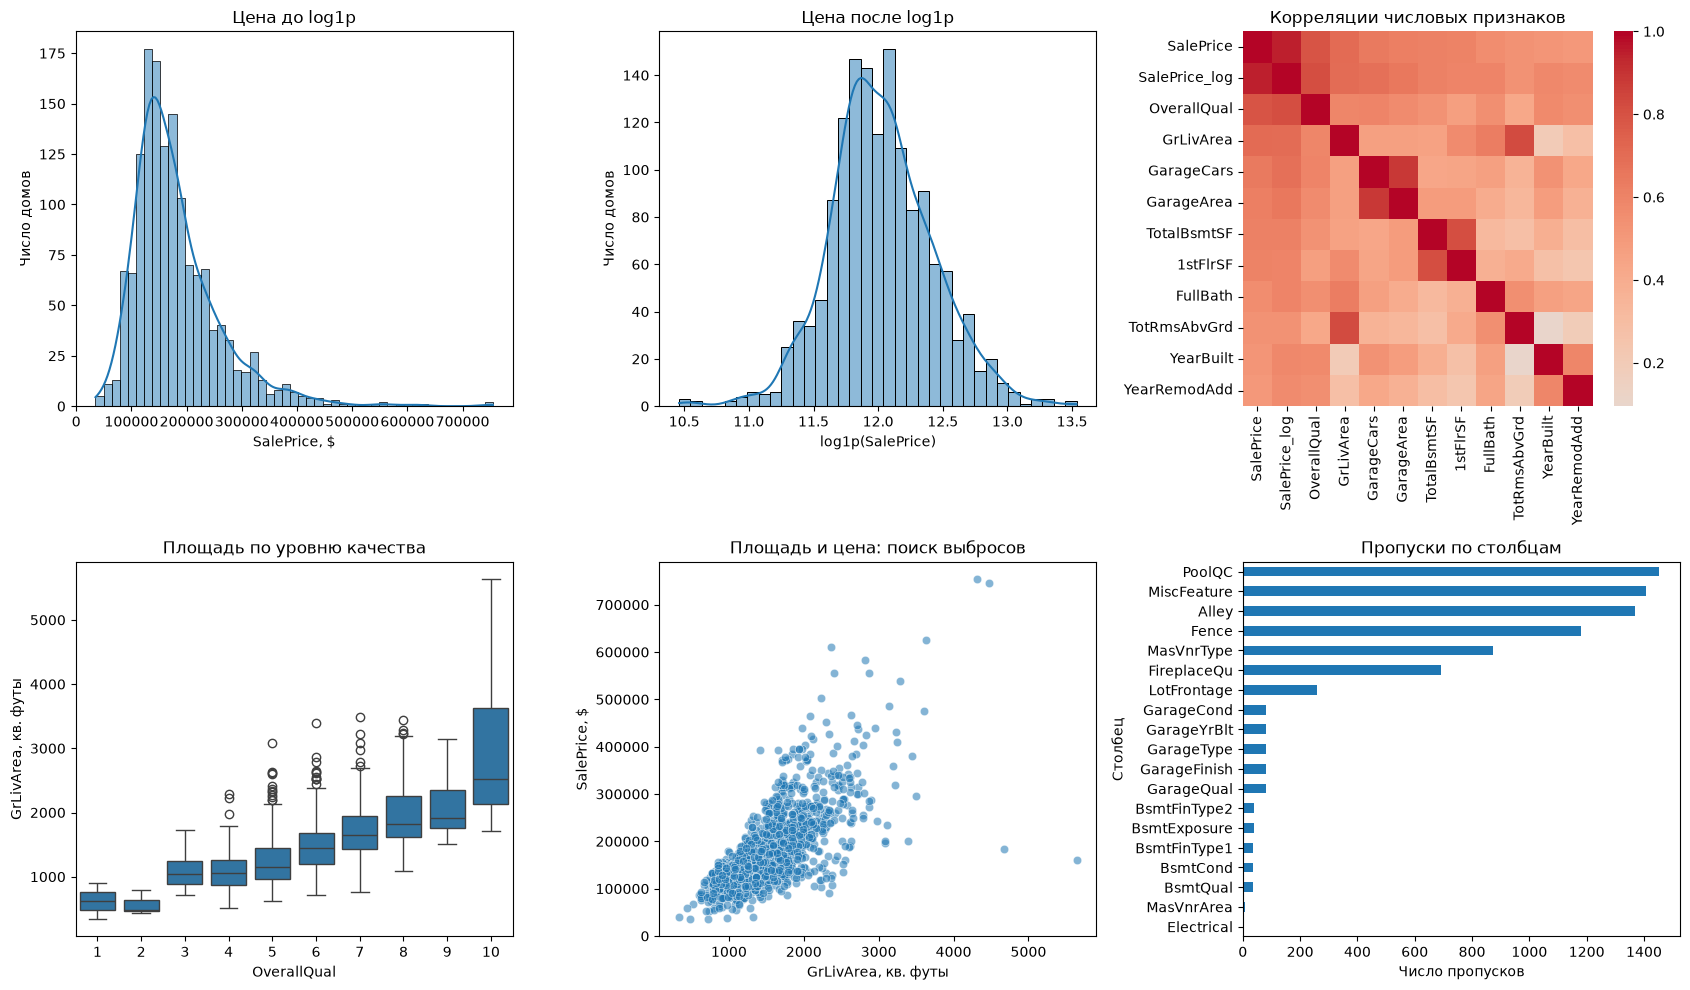

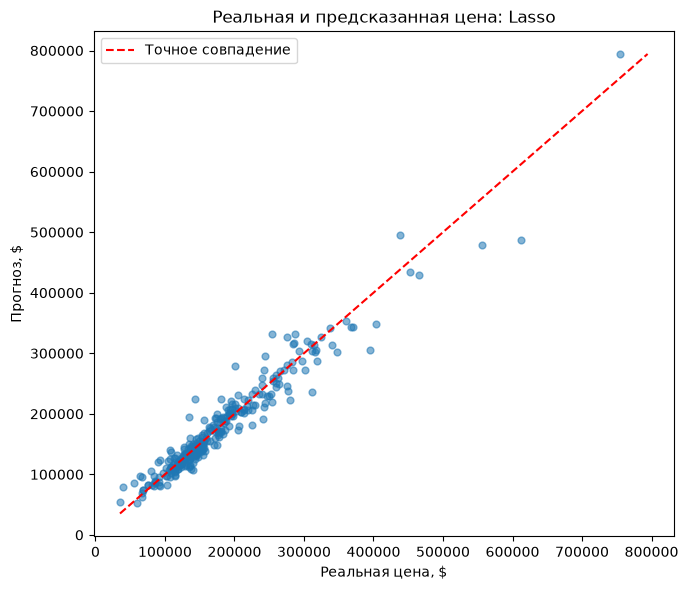

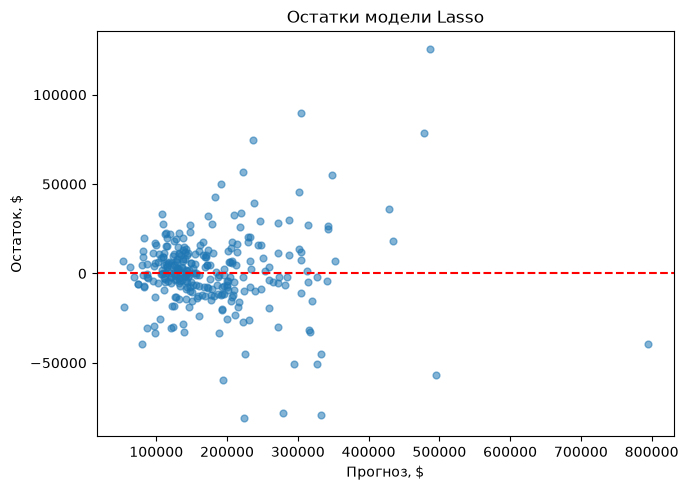

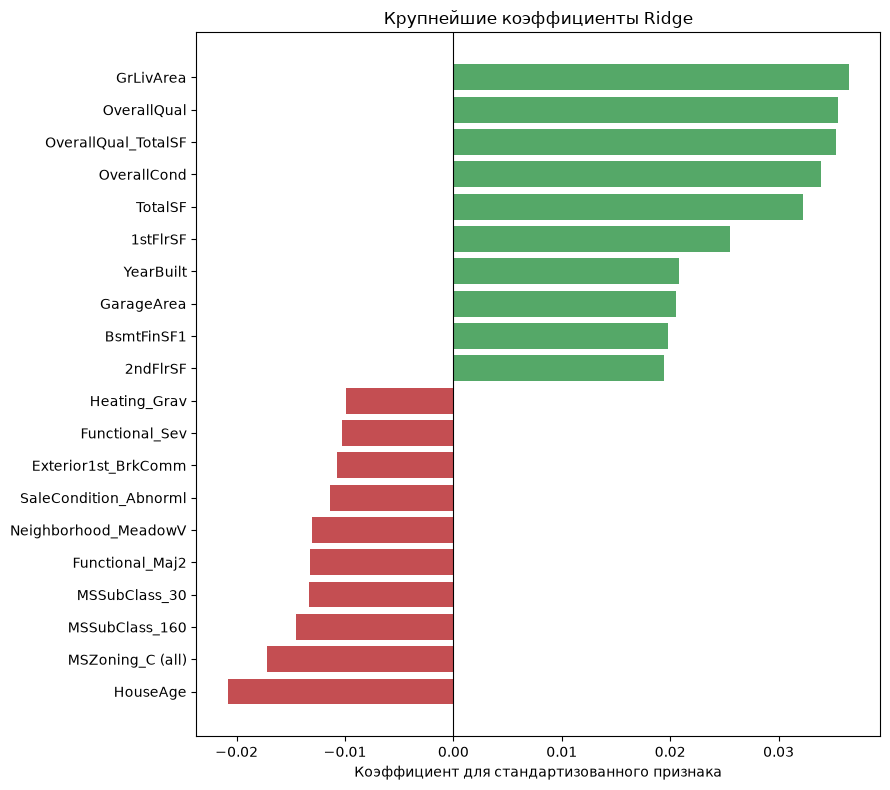

In [17]:
# %%
# Импортируем инструменты анализа и воспроизводимого обучения.
import json
import time
from io import BytesIO
from pathlib import Path
import joblib
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.linear_model import ElasticNet, Lasso, LinearRegression, Ridge
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score
from sklearn.model_selection import GridSearchCV, KFold, train_test_split
from sklearn.preprocessing import StandardScaler

# Пути считаются от папки module-2-house-prices.
DATA_DIR, MODEL_DIR, EXAMPLE_DIR = Path('data'), Path('models'), Path('examples')
MODEL_DIR.mkdir(exist_ok=True)
EXAMPLE_DIR.mkdir(exist_ok=True)
train_df = pd.read_csv(DATA_DIR / 'train.csv')
test_df = pd.read_csv(DATA_DIR / 'test.csv')
print(train_df.shape, test_df.shape)
print('Числовых:', train_df.drop(columns=['Id', 'SalePrice']).select_dtypes(include='number').shape[1])
print('Категориальных:', train_df.select_dtypes(exclude='number').shape[1])
print('SalePrice: mean={:,.0f}, median={:,.0f}, skew={:.3f}, kurtosis={:.3f}'.format(
    train_df.SalePrice.mean(), train_df.SalePrice.median(), train_df.SalePrice.skew(), train_df.SalePrice.kurt()))

# %%
# Просматриваем структуру, типы и первые наблюдения.
print(train_df.head(3).to_string(index=False))
train_df.info()
print(train_df.describe().round(2).to_string())

# Отдельно считаем пропуски и форму распределения цены.
missing = train_df.isna().sum().sort_values(ascending=False)
print('Столбцов с пропусками:', int((missing > 0).sum()))
print(missing[missing > 0].to_string())
print('Skew:', round(train_df.SalePrice.skew(), 3), 'Kurtosis:', round(train_df.SalePrice.kurt(), 3))
train_df['SalePrice_log'] = np.log1p(train_df['SalePrice'])

# %%
# Строим требуемые распределения, связи и пропуски на одной сетке.
fig, axes = plt.subplots(2, 3, figsize=(17, 10))
sns.histplot(train_df.SalePrice, kde=True, ax=axes[0, 0])
axes[0, 0].set(title='Цена до log1p', xlabel='SalePrice, $', ylabel='Число домов')
sns.histplot(train_df.SalePrice_log, kde=True, ax=axes[0, 1])
axes[0, 1].set(title='Цена после log1p', xlabel='log1p(SalePrice)', ylabel='Число домов')
top_corr = train_df.select_dtypes(include='number').corr()['SalePrice'].abs().nlargest(12).index
sns.heatmap(train_df[top_corr].corr(), cmap='coolwarm', center=0, ax=axes[0, 2])
axes[0, 2].set(title='Корреляции числовых признаков')
sns.boxplot(data=train_df, x='OverallQual', y='GrLivArea', ax=axes[1, 0])
axes[1, 0].set(title='Площадь по уровню качества', xlabel='OverallQual', ylabel='GrLivArea, кв. футы')
sns.scatterplot(data=train_df, x='GrLivArea', y='SalePrice', alpha=.55, ax=axes[1, 1])
axes[1, 1].set(title='Площадь и цена: поиск выбросов', xlabel='GrLivArea, кв. футы', ylabel='SalePrice, $')
missing[missing > 0].sort_values().plot.barh(ax=axes[1, 2])
axes[1, 2].set(title='Пропуски по столбцам', xlabel='Число пропусков', ylabel='Столбец')
fig.tight_layout()
fig.savefig(EXAMPLE_DIR / 'eda_plots.png', dpi=150)

# %%
# IQR отмечает крупные дома; доменное условие отделяет подозрительные сделки.
q1, q3 = train_df.GrLivArea.quantile([.25, .75])
iqr_limit = q3 + 1.5 * (q3 - q1)
iqr_flag = train_df.GrLivArea > iqr_limit
domain_flag = (train_df.GrLivArea > 4000) & (train_df.SalePrice < 300000)
print(f'IQR upper: {iqr_limit:.1f}; IQR flagged: {iqr_flag.sum()}; domain outliers: {domain_flag.sum()}')
print('Skew log target:', round(train_df.SalePrice_log.skew(), 3))

# %%
# Фиксируем группы осмысленных пропусков и шкалы качества.
NONE_CATS = ['Alley', 'MasVnrType', 'BsmtQual', 'BsmtCond', 'BsmtExposure',
             'BsmtFinType1', 'BsmtFinType2', 'FireplaceQu', 'GarageType',
             'GarageFinish', 'GarageQual', 'GarageCond', 'PoolQC', 'Fence', 'MiscFeature']
ZERO_NUMS = ['MasVnrArea', 'BsmtFinSF1', 'BsmtFinSF2', 'BsmtUnfSF', 'TotalBsmtSF',
             'BsmtFullBath', 'BsmtHalfBath', 'GarageYrBlt', 'GarageCars', 'GarageArea']
QUALITY = {'None': 0, 'Po': 1, 'Fa': 2, 'TA': 3, 'Gd': 4, 'Ex': 5}
ORDINAL_MAPS = {c: QUALITY for c in ['ExterQual', 'ExterCond', 'BsmtQual', 'BsmtCond',
                'HeatingQC', 'KitchenQual', 'FireplaceQu', 'GarageQual', 'GarageCond', 'PoolQC']}
ORDINAL_MAPS.update({'BsmtExposure': {'None': 0, 'No': 1, 'Mn': 2, 'Av': 3, 'Gd': 4},
                     'BsmtFinType1': {'None': 0, 'Unf': 1, 'LwQ': 2, 'Rec': 3, 'BLQ': 4, 'ALQ': 5, 'GLQ': 6},
                     'BsmtFinType2': {'None': 0, 'Unf': 1, 'LwQ': 2, 'Rec': 3, 'BLQ': 4, 'ALQ': 5, 'GLQ': 6},
                     'GarageFinish': {'None': 0, 'Unf': 1, 'RFn': 2, 'Fin': 3}})

# Сначала разделяем исходные строки, затем исключаем два аномальных дома из обучения.
raw_train, raw_valid = train_test_split(train_df, test_size=.2, random_state=42)
train_outliers = (raw_train.GrLivArea > 4000) & (raw_train.SalePrice < 300000)
raw_train = raw_train.loc[~train_outliers].copy()
print('Обучение:', len(raw_train), 'Проверка:', len(raw_valid), 'Исключено из обучения:', int(train_outliers.sum()))

# %%
# Параметры заполнения оцениваем исключительно на обучающих строках.
def fit_preprocessor(frame):
    base = frame.drop(columns=['Id', 'SalePrice', 'SalePrice_log'], errors='ignore').copy()
    base['MSSubClass'] = base.MSSubClass.astype(str)
    num_cols = list(base.select_dtypes(include='number').columns)
    cat_cols = list(base.select_dtypes(exclude='number').columns)
    return {
        'base_cols': list(base.columns), 'num_cols': num_cols, 'cat_cols': cat_cols,
        'frontage_by_neighborhood': base.groupby('Neighborhood').LotFrontage.median().to_dict(),
        'frontage_global': float(base.LotFrontage.median()),
        'numeric_medians': {c: float(base[c].median()) for c in num_cols if c not in ZERO_NUMS + ['LotFrontage']},
        'categorical_modes': {c: str(base[c].mode(dropna=True).iloc[0]) for c in cat_cols if c not in NONE_CATS},
    }

# Одинаковая функция применяет сохранённые правила к обучению, проверке и новым домам.
def transform_raw(frame, prep, feature_cols=None):
    x = frame.reindex(columns=prep['base_cols']).copy()
    x['MSSubClass'] = x.MSSubClass.astype(str)
    for col in NONE_CATS:
        x[col] = x[col].fillna('None')
    for col in ZERO_NUMS:
        x[col] = x[col].fillna(0)
    frontage = x['Neighborhood'].map(prep['frontage_by_neighborhood'])
    x['LotFrontage'] = x.LotFrontage.fillna(frontage).fillna(prep['frontage_global'])
    for col, value in prep['numeric_medians'].items():
        x[col] = x[col].fillna(value)
    for col, value in prep['categorical_modes'].items():
        x[col] = x[col].fillna(value)
    for col, mapping in ORDINAL_MAPS.items():
        x[col] = x[col].map(mapping).fillna(0).astype(float)
    x['TotalSF'] = x.TotalBsmtSF + x['1stFlrSF'] + x['2ndFlrSF']
    x['TotalBath'] = x.FullBath + .5*x.HalfBath + x.BsmtFullBath + .5*x.BsmtHalfBath
    x['TotalPorch'] = x[['WoodDeckSF', 'OpenPorchSF', 'EnclosedPorch', '3SsnPorch', 'ScreenPorch']].sum(axis=1)
    x['HouseAge'] = x.YrSold - x.YearBuilt
    x['RemodAge'] = x.YrSold - x.YearRemodAdd
    x['HasPool'] = (x.PoolArea > 0).astype(int)
    x['HasGarage'] = (x.GarageCars > 0).astype(int)
    x['Has2ndFloor'] = (x['2ndFlrSF'] > 0).astype(int)
    x['HasFireplace'] = (x.Fireplaces > 0).astype(int)
    x['OverallQual_TotalSF'] = x.OverallQual * x.TotalSF
    x = pd.get_dummies(x, columns=list(x.select_dtypes(exclude='number').columns), dtype=float)
    if feature_cols is not None:
        x = x.reindex(columns=feature_cols, fill_value=0)
    return x.astype(float)

# Проверяем, что ни один признак не остался с NaN и колонки совпадают.
preprocessor = fit_preprocessor(raw_train)
X_train = transform_raw(raw_train, preprocessor)
feature_cols = list(X_train.columns)
X_valid = transform_raw(raw_valid, preprocessor, feature_cols)
X_competition = transform_raw(test_df, preprocessor, feature_cols)
y_train, y_valid = raw_train.SalePrice_log, raw_valid.SalePrice_log
assert not X_train.isna().any().any() and not X_valid.isna().any().any()
assert list(X_train.columns) == list(X_valid.columns) == list(X_competition.columns)
print('Признаков после кодирования:', len(feature_cols), 'NaN:', int(X_train.isna().sum().sum()))
print('Feature Engineering:', [c for c in ['TotalSF', 'TotalBath', 'TotalPorch', 'HouseAge', 'RemodAge', 'HasPool', 'HasGarage', 'Has2ndFloor', 'HasFireplace', 'OverallQual_TotalSF'] if c in feature_cols])

# %%
# Масштабируем числовую матрицу после деления на обучение и проверку.
scaler = StandardScaler()
X_train_scaled = scaler.fit_transform(X_train)
X_valid_scaled = scaler.transform(X_valid)
cv = KFold(n_splits=5, shuffle=True, random_state=42)
models, train_times, cv_scores, best_params = {}, {}, {}, {}

# Базовая модель не имеет подбираемых гиперпараметров.
start = time.perf_counter()
models['Linear Regression'] = LinearRegression().fit(X_train_scaled, y_train)
train_times['Linear Regression'] = time.perf_counter() - start
best_params['Linear Regression'] = {}
cv_scores['Linear Regression'] = np.nan

# Подбор идёт только по обучающей части; отложенная часть остаётся нетронутой.
search_spaces = {
    'Ridge': (Ridge(), {'alpha': [1.0, 10.0, 100.0]}),
    'Lasso': (Lasso(max_iter=30000, random_state=42), {'alpha': [.0002, .0005, .001, .002]}),
    'ElasticNet': (ElasticNet(max_iter=30000, random_state=42),
                   {'alpha': [.0005, .001, .002], 'l1_ratio': [.3, .5, .8]})
}
for name, (estimator, grid) in search_spaces.items():
    search = GridSearchCV(estimator, grid, cv=cv, scoring='neg_root_mean_squared_error', n_jobs=1)
    start = time.perf_counter()
    search.fit(X_train_scaled, y_train)
    train_times[name] = time.perf_counter() - start
    models[name] = search.best_estimator_
    best_params[name] = search.best_params_
    cv_scores[name] = -search.best_score_
    print(name, best_params[name], 'CV RMSE(log)=', round(cv_scores[name], 5),
          'search time(s)=', round(train_times[name], 3))
print('Linear Regression training time(s)=', round(train_times['Linear Regression'], 3))

# %%
# Возвращаем прогноз из логарифмов к цене для метрик в долларах.
def evaluate_model(model, x_scaled, y_log):
    predicted_log = model.predict(x_scaled)
    actual_dollars, predicted_dollars = np.expm1(y_log), np.expm1(predicted_log)
    return {'rmse_log': float(np.sqrt(mean_squared_error(y_log, predicted_log))),
            'mae_log': float(mean_absolute_error(y_log, predicted_log)),
            'r2_log': float(r2_score(y_log, predicted_log)),
            'rmse_dollars': float(np.sqrt(mean_squared_error(actual_dollars, predicted_dollars))),
            'mae_dollars': float(mean_absolute_error(actual_dollars, predicted_dollars))}

# Сравниваем все модели на одной отложенной части.
metrics = {name: evaluate_model(model, X_valid_scaled, y_valid) for name, model in models.items()}
best_name = min(('Ridge', 'Lasso', 'ElasticNet'), key=lambda name: cv_scores[name])
best_model = models[best_name]
metrics_table = pd.DataFrame(metrics).T
print(metrics_table.round(5).to_string())
print('Лучшая по CV:', best_name, 'R²(log) на проверке:', round(metrics[best_name]['r2_log'], 4))

# %%
# Сопоставляем реальные и предсказанные цены лучшей модели.
y_true_dollars = np.expm1(y_valid.to_numpy())
y_pred_dollars = np.expm1(best_model.predict(X_valid_scaled))
fig, ax = plt.subplots(figsize=(7, 6))
ax.scatter(y_true_dollars, y_pred_dollars, alpha=.55, s=24)
limits = [min(y_true_dollars.min(), y_pred_dollars.min()), max(y_true_dollars.max(), y_pred_dollars.max())]
ax.plot(limits, limits, 'r--', label='Точное совпадение')
ax.set(title=f'Реальная и предсказанная цена: {best_name}', xlabel='Реальная цена, $', ylabel='Прогноз, $')
ax.legend()
fig.tight_layout()
fig.savefig(EXAMPLE_DIR / 'predictions_scatter.png', dpi=150)

# %%
# Остатки считаются как истинная цена минус прогноз в долларах.
residuals = y_true_dollars - y_pred_dollars
fig, ax = plt.subplots(figsize=(7, 5))
ax.scatter(y_pred_dollars, residuals, alpha=.55, s=24)
ax.axhline(0, color='red', linestyle='--')
ax.set(title=f'Остатки модели {best_name}', xlabel='Прогноз, $', ylabel='Остаток, $')
fig.tight_layout()
fig.savefig(EXAMPLE_DIR / 'residuals.png', dpi=150)
print('Среднее остатков: ${:,.0f}; стандартное отклонение: ${:,.0f}'.format(residuals.mean(), residuals.std()))
print('Медиана абсолютной ошибки: ${:,.0f}'.format(np.median(np.abs(residuals))))

# %%
# Показываем самые сильные положительные и отрицательные веса Ridge.
ridge_coef = pd.Series(models['Ridge'].coef_, index=feature_cols)
top_positive = ridge_coef.nlargest(10)
top_negative = ridge_coef.nsmallest(10)
print('Ridge: положительные\n', top_positive.round(4).to_string())
print('Ridge: отрицательные\n', top_negative.round(4).to_string())
fig, ax = plt.subplots(figsize=(9, 8))
selected = pd.concat([top_negative, top_positive]).sort_values()
ax.barh(selected.index, selected.values, color=['#c44e52' if value < 0 else '#55a868' for value in selected])
ax.axvline(0, color='black', linewidth=.8)
ax.set(title='Крупнейшие коэффициенты Ridge', xlabel='Коэффициент для стандартизованного признака')
fig.tight_layout()

# %%
# Нулевые коэффициенты Lasso показывают фактический отбор столбцов.
lasso_coef = pd.Series(models['Lasso'].coef_, index=feature_cols)
n_zero = int(np.isclose(lasso_coef, 0, atol=1e-10).sum())
n_total = len(lasso_coef)
print(f'Lasso обнулил {n_zero} из {n_total} признаков; осталось {n_total - n_zero}.')
print('Сильнейшие ненулевые:\n', lasso_coef[~np.isclose(lasso_coef, 0, atol=1e-10)].abs().nlargest(15).round(4).to_string())
print('Корреляция GarageCars и GarageArea:', round(train_df[['GarageCars', 'GarageArea']].corr().iloc[0, 1], 3))
pool_prices = train_df.groupby(train_df.PoolArea.gt(0)).SalePrice.agg(['count', 'mean'])
print('Цена по наличию бассейна (описательно, без поправок):\n', pool_prices.round(0).to_string())

# %%
# Дополнительный аргумент хранит правила обработки сырых домов.
def predict_price(house_data, model, scaler, feature_cols, preprocessor=preprocessor):
    """Возвращает прогноз цены в долларах для словаря исходных полей дома."""
    x_raw = pd.DataFrame([house_data])
    x_features = transform_raw(x_raw, preprocessor, feature_cols)
    x_scaled = scaler.transform(x_features)
    return float(np.expm1(model.predict(x_scaled)[0]))

# Берём разнообразные реальные профили без известных целевых цен.
targets = [(9, 2800), (6, 1500), (4, 900), (10, 4000), (5, 1200)]
available = test_df.copy()
profiles = []
for quality, area in targets:
    distance = (available.OverallQual - quality).abs()*600 + (available.GrLivArea - area).abs()
    idx = distance.idxmin()
    profiles.append(available.loc[idx].to_dict())
    available = available.drop(index=idx)

# Выводим профиль и прогноз каждой из обязательных моделей.
for i, house in enumerate(profiles, 1):
    description = {key: house[key] for key in ['Id', 'OverallQual', 'GrLivArea', 'YearBuilt', 'GarageCars', 'FullBath', 'HalfBath']}
    predictions = {name: round(predict_price(house, model, scaler, feature_cols)) for name, model in models.items()}
    print(f'Дом {i}: {description}; прогнозы ($): {predictions}')

# %%
# Записываем модели и все объекты, необходимые для повторного инференса.
filenames = {'Linear Regression': 'lr_model.pkl', 'Ridge': 'ridge_model.pkl',
             'Lasso': 'lasso_model.pkl', 'ElasticNet': 'enet_model.pkl'}
for name, filename in filenames.items():
    joblib.dump(models[name], MODEL_DIR / filename)
joblib.dump(best_model, MODEL_DIR / 'best_model.pkl')
joblib.dump(scaler, MODEL_DIR / 'scaler.pkl')
joblib.dump(preprocessor, MODEL_DIR / 'preprocessor.pkl')

# Метаданные сохраняем в обычном JSON для просмотра без Python.
(MODEL_DIR / 'feature_cols.json').write_text(json.dumps(feature_cols, ensure_ascii=False, indent=2), encoding='utf-8')
report = {'selection_metric': 'five-fold CV RMSE on log1p(SalePrice)', 'best_model': best_name,
          'models': {name: {**values, 'train_time_sec': float(train_times[name]),
                            'cv_rmse_log': None if np.isnan(cv_scores[name]) else float(cv_scores[name]),
                            'parameters': best_params[name]} for name, values in metrics.items()},
          'lasso_features_selected': int(n_total - n_zero), 'lasso_features_dropped': int(n_zero),
          'training_rows': len(raw_train), 'validation_rows': len(raw_valid),
          'removed_training_outliers': int(train_outliers.sum()), 'feature_count': len(feature_cols)}
(MODEL_DIR / 'metrics.json').write_text(json.dumps(report, ensure_ascii=False, indent=2), encoding='utf-8')
print('Сохранены:', ', '.join(sorted(path.name for path in MODEL_DIR.iterdir())))

# %%
# Локальная загрузка имитирует повторный запуск без обучения.
loaded_model = joblib.load(MODEL_DIR / 'best_model.pkl')
loaded_scaler = joblib.load(MODEL_DIR / 'scaler.pkl')
loaded_preprocessor = joblib.load(MODEL_DIR / 'preprocessor.pkl')
loaded_features = json.loads((MODEL_DIR / 'feature_cols.json').read_text(encoding='utf-8'))
for i, house in enumerate(profiles[:3], 1):
    original = predict_price(house, best_model, scaler, feature_cols)
    restored = predict_price(house, loaded_model, loaded_scaler, loaded_features, loaded_preprocessor)
    assert np.isclose(original, restored, rtol=0, atol=1e-8)
    print(f'Дом {i}: исходный ${original:,.2f}; загруженный ${restored:,.2f}; совпали')

# %%
# Публикация выполнена; загружаем четыре артефакта по raw-ссылкам.
BASE_URL = 'https://raw.githubusercontent.com/VolodinaAlexandra/ml-course-volodina/main/module-2-house-prices'

def load_published_artifacts(base_url=BASE_URL):
    """Скачивает модель и подготовку из опубликованной ветки main."""
    import requests
    def download(relative_path):
        response = requests.get(f'{base_url}/{relative_path}', timeout=30)
        response.raise_for_status()
        return response.content
    model = joblib.load(BytesIO(download('models/best_model.pkl')))
    scale = joblib.load(BytesIO(download('models/scaler.pkl')))
    prep = joblib.load(BytesIO(download('models/preprocessor.pkl')))
    features = json.loads(download('models/feature_cols.json').decode('utf-8'))
    return model, scale, features, prep

# Сверяем порядок признаков и три прогноза с локально обученной моделью.
remote_model, remote_scaler, remote_features, remote_preprocessor = load_published_artifacts()
assert remote_features == feature_cols
for i, house in enumerate(profiles[:3], 1):
    local_price = predict_price(house, best_model, scaler, feature_cols)
    remote_price = predict_price(house, remote_model, remote_scaler, remote_features, remote_preprocessor)
    assert np.isclose(local_price, remote_price, rtol=0, atol=1e-8)
    print(f'GitHub raw, дом {i}: ${remote_price:,.2f}; прогноз совпал')
